In [21]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras

In [22]:
import tensorflow as tf

train = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Train",
    image_size=(224, 224),
    batch_size=32,
    shuffle=True
)

val = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

Found 4218 files belonging to 4 classes.
Found 787 files belonging to 4 classes.
Found 789 files belonging to 4 classes.


In [23]:
def preprocess(images, labels):
    images = tf.cast(images, tf.float32)
    images = images / 127.5 - 1
    return images, labels

train = train.map(preprocess)
val = val.map(preprocess)
test = test.map(preprocess)

In [24]:


base_model = keras.applications.InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3),
    pooling="avg"
)

base_model.trainable = False


In [25]:
model = keras.Sequential([
    keras.layers.Input(shape=(224, 224, 3)),

    # Redimensionner les images
    keras.layers.Resizing(299, 299),

    # Prétraiter les pixels pour InceptionV3
    keras.layers.Lambda(
        keras.applications.inception_v3.preprocess_input
    ),

    # Extraire les caractéristiques
    base_model,

    # Réduire le surapprentissage
    keras.layers.Dropout(0.4),

    # Classifier les 4 catégories
    keras.layers.Dense(4, activation="softmax")
])

In [26]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing_2 (Resizing)       (None, 299, 299, 3)       0         
                                                                 
 lambda_2 (Lambda)           (None, 299, 299, 3)       0         
                                                                 
 inception_v3 (Functional)   (None, 2048)              21802784  
                                                                 
 dropout_2 (Dropout)         (None, 2048)              0         
                                                                 
 dense_2 (Dense)             (None, 4)                 8196      
                                                                 
Total params: 21810980 (83.20 MB)
Trainable params: 8196 (32.02 KB)
Non-trainable params: 21802784 (83.17 MB)
_________________________________________________________________


In [27]:
history = model.fit(
    train,
    validation_data=val,
    epochs=10
)

Epoch 1/10


W0000 00:00:1792682308.786260  540932 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.77GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792682309.132570  540932 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.40GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


131/132 [============================>.] - ETA: 0s - loss: 1.0113 - accuracy: 0.5661

W0000 00:00:1792682330.625264  540934 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.63GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1792682330.918576  540934 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.31GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


132/132 [==============================] - 33s 218ms/step - loss: 1.0108 - accuracy: 0.5661 - val_loss: 0.8969 - val_accuracy: 0.6442
Epoch 2/10
132/132 [==============================] - 23s 176ms/step - loss: 0.7948 - accuracy: 0.6721 - val_loss: 0.8173 - val_accuracy: 0.6696
Epoch 3/10
132/132 [==============================] - 23s 176ms/step - loss: 0.7221 - accuracy: 0.7037 - val_loss: 0.7572 - val_accuracy: 0.7128
Epoch 4/10
132/132 [==============================] - 23s 176ms/step - loss: 0.6838 - accuracy: 0.7188 - val_loss: 0.7262 - val_accuracy: 0.7319
Epoch 5/10
132/132 [==============================] - 23s 176ms/step - loss: 0.6462 - accuracy: 0.7413 - val_loss: 0.6769 - val_accuracy: 0.7306
Epoch 6/10
132/132 [==============================] - 23s 176ms/step - loss: 0.6300 - accuracy: 0.7451 - val_loss: 0.6692 - val_accuracy: 0.7421
Epoch 7/10
132/132 [==============================] - 23s 176ms/step - loss: 0.6040 - accuracy: 0.7606 - val_loss: 0.6466 - val_accuracy: 0.7

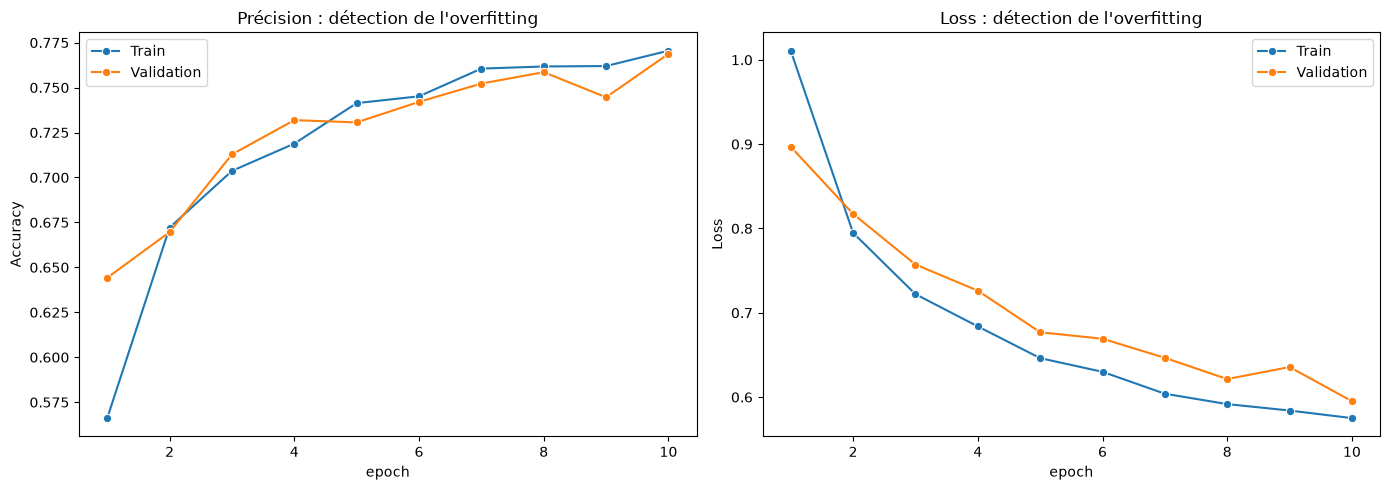

In [28]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame(history.history)

df["epoch"] = range(1, len(df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=df, x="epoch", y="accuracy",
             marker="o", label="Train", ax=axes[0])

sns.lineplot(data=df, x="epoch", y="val_accuracy",
             marker="o", label="Validation", ax=axes[0])

axes[0].set_title("Précision : détection de l'overfitting")
axes[0].set_ylabel("Accuracy")

sns.lineplot(data=df, x="epoch", y="loss",
             marker="o", label="Train", ax=axes[1])

sns.lineplot(data=df, x="epoch", y="val_loss",
             marker="o", label="Validation", ax=axes[1])

axes[1].set_title("Loss : détection de l'overfitting")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()
